<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Preperation
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Import important libraries and data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop, Adam
from keras_tuner.tuners import RandomSearch
from helper_functions import create_sequences_lstm, update_sequence

In [3]:
# Import the Data
utilization = pd.read_csv('utilization_final.csv')

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Prepare the data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [4]:
# Convert the ingap variable to an int
utilization['in_gap'] = utilization['in_gap'].astype(int)

# Convert the 'timestamp' column to the pandas datetime format
utilization['timestamp'] = pd.to_datetime(utilization['timestamp'])

# Cut the data at the point where covid started
cutoff_time = pd.to_datetime('2020-03-18 23:59:59')
duplicate_rows = utilization[utilization['timestamp'] < cutoff_time].index
utilization.drop(duplicate_rows,inplace=True)

In [5]:
# Drop the columns we don't need for the model from here
utilization.drop(['utilization_absolute', 
       'precipitation', 
        'hour','winter','autumn','summer','friday','day_of_week'],axis=1,inplace=True)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        3. Scale the Data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [6]:
# Scale the features to (0, 1)
scaler = MinMaxScaler()
scaled_columns = ['utilization_perc', 'temperature', 'site_01',
       'hour_sin', 'hour_cos',  'weekday_sin', 'weekday_cos',
       'month_sin', 'month_cos', 'in_gap','stay_at_home','weekday','month','weekend']
utilization[scaled_columns] = scaler.fit_transform(utilization[scaled_columns])

# Convert to a DataFrame
utilization = pd.DataFrame(utilization, columns=utilization.columns)

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        4. Prepare the Test-Train-Split
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [7]:
# Split the data 
train_data = utilization[utilization['timestamp'] < '2021-08-16'].copy()
test_data = utilization[(utilization['timestamp'] >= '2021-08-16') & (utilization['timestamp'] < '2021-09-13 19:00')].copy()

# Create a 'date' column for grouping
train_data["date"] = train_data["timestamp"].dt.date
test_data["date"] = test_data["timestamp"].dt.date

# Sort by date, then by site, and then by timestamp
train_data = train_data.sort_values(by=["date", "site_01", "timestamp"]).reset_index(drop=True)
test_data = test_data.sort_values(by=["date", "site_01", "timestamp"]).reset_index(drop=True)

# Drop the timestamp column
train_data.drop(['timestamp','date'],axis=1,inplace = True)
test_data.drop(['date'],axis=1,inplace = True)

In [8]:
# Define sequence length 
sequence_length = 24
target_column = "utilization_perc"
X, y = create_sequences_lstm(train_data, sequence_length, target_column)

# Check shapes
print("Input shape (X):", X.shape)  # (samples, sequence_length, features)
print("Output shape (y):", y.shape)  # (samples,)

Input shape (X): (24586, 24, 15)
Output shape (y): (24586,)


In [9]:
# Split into training and testing sets
split = int(0.8 * len(X))
X_train, X_val = X[:split], X[split:]
y_train, y_val = y[:split], y[split:]

<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Model
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        1. Train the Model
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [10]:
model = Sequential([
    Input(shape=(sequence_length, X.shape[2])),  
    LSTM(32, activation='tanh', return_sequences=False),
    Dense(16, activation='relu'),
    Dense(1)
])

# Compile the model
optimizer = RMSprop(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mae')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,689 (26.13 KB)

 Trainable params: 6,689 (26.13 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,  
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0416 - val_loss: 0.0305
Epoch 2/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0157 - val_loss: 0.0257
Epoch 3/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0133 - val_loss: 0.0259
Epoch 4/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0120 - val_loss: 0.0234
Epoch 5/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0111 - val_loss: 0.0207
Epoch 6/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0106 - val_loss: 0.0257
Epoch 7/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0101 - val_loss: 0.0203
Epoch 8/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0100 - val_loss: 0.0200
Epoch 9/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0098 - val_loss: 0.0200
Epoch 10/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0097 - val_loss: 0.0191
Epoch 11/100
1230/1230 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0096 - val_loss: 0.0198
Epoch 12/100
1230/1

In [37]:
best_mae_index = history.history['val_loss'].index(min(history.history['val_loss']))
best_mae = history.history['val_loss'][best_mae_index]

print(f"Best Validation MAE: {best_mae:.5f} at Epoch {best_mae_index + 1}")

Best Validation MAE: 0.01781 at Epoch 23


<span style ="font-size: 18px; font-weight: bold;color: #43556A;">
        2. Test the model
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [38]:
# Split the test data to get results for each site
test_data1 = test_data[test_data['site_01']==1]
test_data2 = test_data[test_data['site_01']==0]

# Create sequences from the data
X_test_1, y_test_1 = create_sequences_lstm(test_data1.drop(['timestamp'],axis=1), sequence_length, target_column)
X_test_2, y_test_2 = create_sequences_lstm(test_data2.drop(['timestamp'],axis=1), sequence_length, target_column)

In [39]:
# Create empty lists to store the predictions
predictions_1 = []
predictions_2 = []

# Get the predictions for each site
input_sequence = X_test_1[0]  
for i in range(667):  
    input_sequence = X_test_1[i]
    pred = model.predict(input_sequence.reshape(1, 24, 15),verbose=0)
    predictions_1.extend(pred[0]) 
    i += 1 
    
input_sequence = X_test_2[0]  
for i in range(667):  
    input_sequence = X_test_2[i]
    pred = model.predict(input_sequence.reshape(1, 24, 15),verbose=0)
    predictions_2.extend(pred[0])  
    i += 1
    
mae_1 = mean_absolute_error(y_test_1, predictions_1)
mae_2 = mean_absolute_error(y_test_2, predictions_2)
print(f"Mean Absolute Error (MAE) for site 01: {mae_1}")
print(f"Mean Absolute Error (MAE) for site 02: {mae_2}")

Mean Absolute Error (MAE) for site 01: 0.030952302605563982
Mean Absolute Error (MAE) for site 02: 0.019254940923517504


<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Visualizations
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [40]:
test_data1 = test_data1[24:].copy()
test_data2= test_data2[24:].copy()

test_data1['predictions_site_01'] = predictions_1
test_data2['predictions_site_01'] = predictions_2

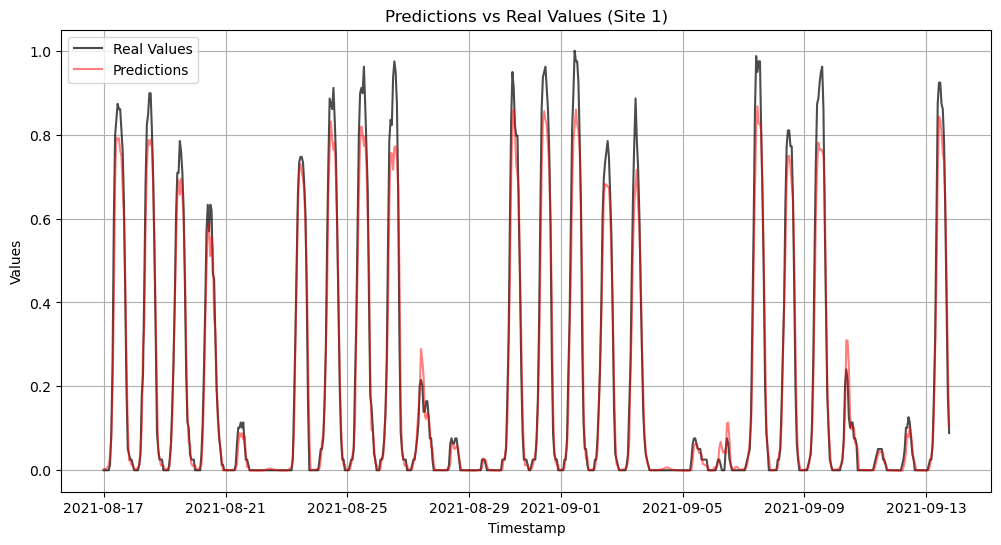

In [41]:
# Calculate the residuals for the first site
test_data1['residuals'] = test_data1['utilization_perc'] - test_data1['predictions_site_01']
# Add a column for weekdays
test_data1['weekday'] = test_data1['timestamp'].dt.day_name()  

# Plot the Predictions
plt.figure(figsize=(12, 6))

plt.plot(test_data1['timestamp'], test_data1['utilization_perc'], label='Real Values', color='black', alpha=0.7)
plt.plot(test_data1['timestamp'], test_data1['predictions_site_01'], label='Predictions', color='red', alpha=0.5)

plt.title('Predictions vs Real Values (Site 1)')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.legend()
plt.grid()
plt.show()

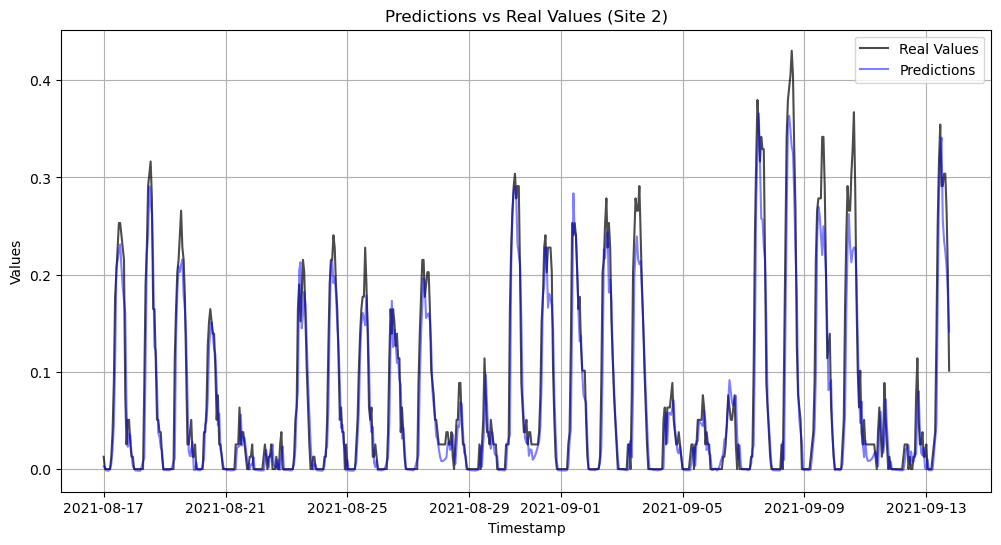

In [42]:
# Calculate the residuals for the second site
test_data2['residuals'] = test_data2['utilization_perc'] - test_data2['predictions_site_01']

# Add a column for weekdays
test_data2['weekday'] = test_data2['timestamp'].dt.day_name()  

# Plot the Predictions
plt.figure(figsize=(12, 6))

plt.plot(test_data2['timestamp'], test_data2['utilization_perc'], label='Real Values', color='black', alpha=0.7)
plt.plot(test_data2['timestamp'], test_data2['predictions_site_01'], label='Predictions', color='blue', alpha=0.5)

plt.title('Predictions vs Real Values (Site 2)')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.legend()
plt.grid()
plt.show()

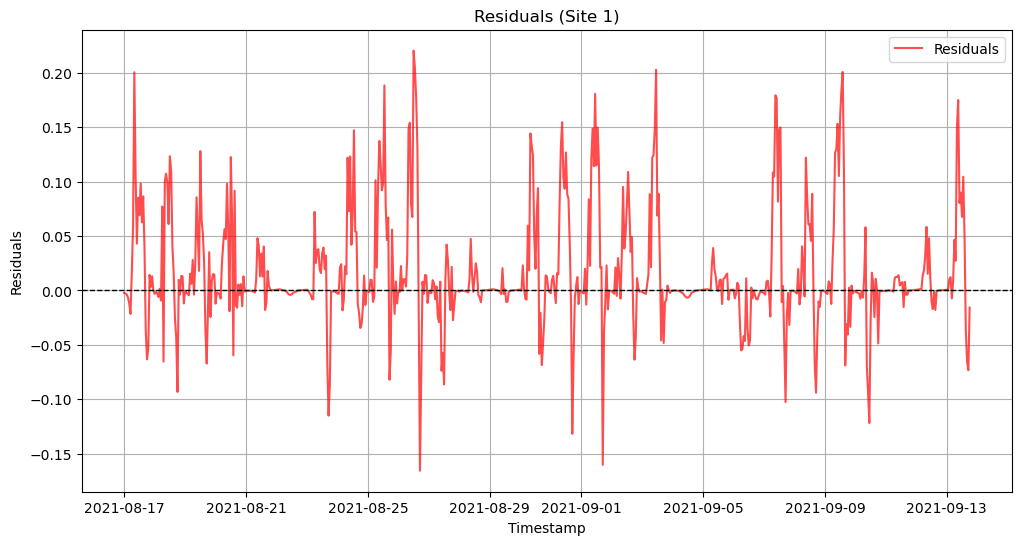

In [43]:
# Plot the residuals for the first site
plt.figure(figsize=(12, 6))

plt.plot(test_data1['timestamp'], test_data1['residuals'], label='Residuals', color='red', alpha=0.7)
plt.axhline(0, color='black', linestyle='--', linewidth=1)  

plt.title('Residuals (Site 1)')
plt.xlabel('Timestamp')
plt.ylabel('Residuals')
plt.legend()
plt.grid()
plt.show()


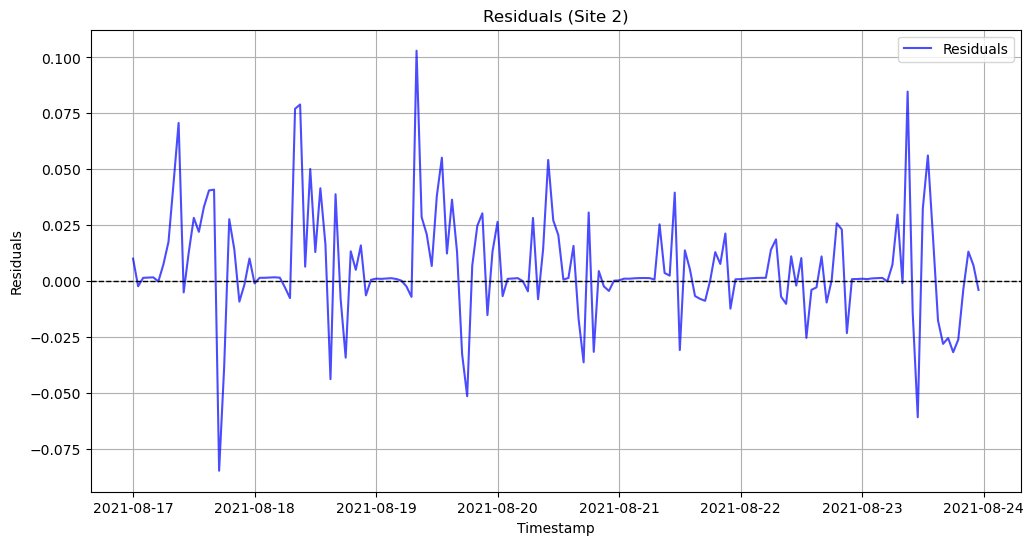

In [44]:
# Plot the residuals for the second site
plt.figure(figsize=(12, 6))

plt.plot(test_data2['timestamp'][:168], test_data2['residuals'][:168], label='Residuals', color='blue', alpha=0.7)
plt.axhline(0, color='black', linestyle='--', linewidth=1)  

plt.title('Residuals (Site 2)')
plt.xlabel('Timestamp')
plt.ylabel('Residuals')
plt.legend()
plt.grid()
plt.show()

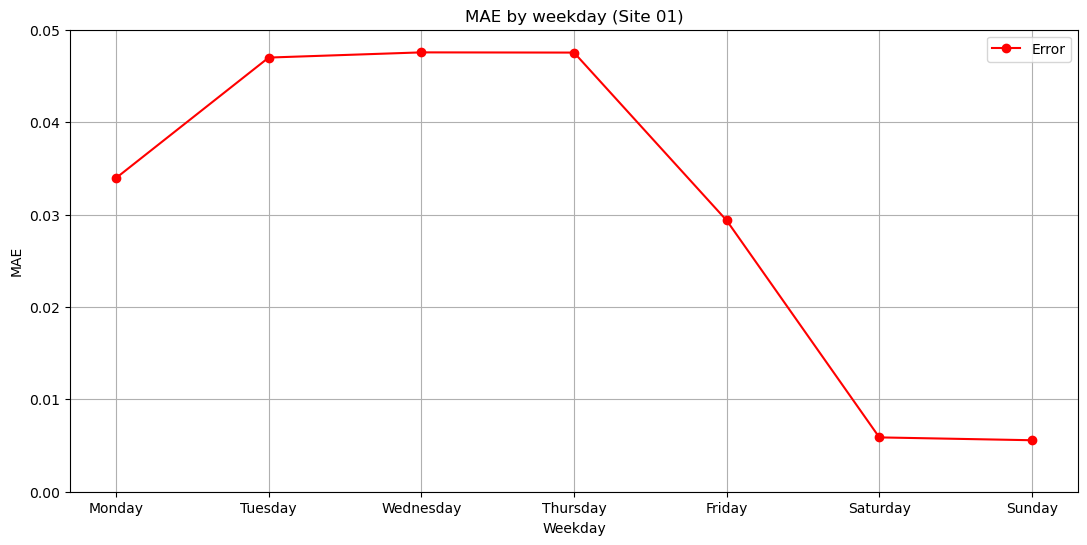

In [62]:
# Convert the residuals to absolutes and get the average
test_data1['residuals'] = test_data1['residuals'].abs()
weekday_avg = test_data1.groupby('weekday').mean(numeric_only=True)
weekday_avg = weekday_avg.reset_index()

# Sort weekdays 
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_avg['weekday'] = pd.Categorical(weekday_avg['weekday'], categories=weekday_order, ordered=True)
weekday_avg = weekday_avg.sort_values('weekday')

# Plotting
plt.figure(figsize=(13, 6))
plt.plot(weekday_avg['weekday'], weekday_avg['residuals'], marker='o', label='Error',color='red')
plt.xlabel('Weekday')
plt.ylabel('MAE')
plt.ylim(0,0.05)
plt.title('MAE by weekday (Site 01)')
plt.legend()
plt.grid(True)
plt.show()

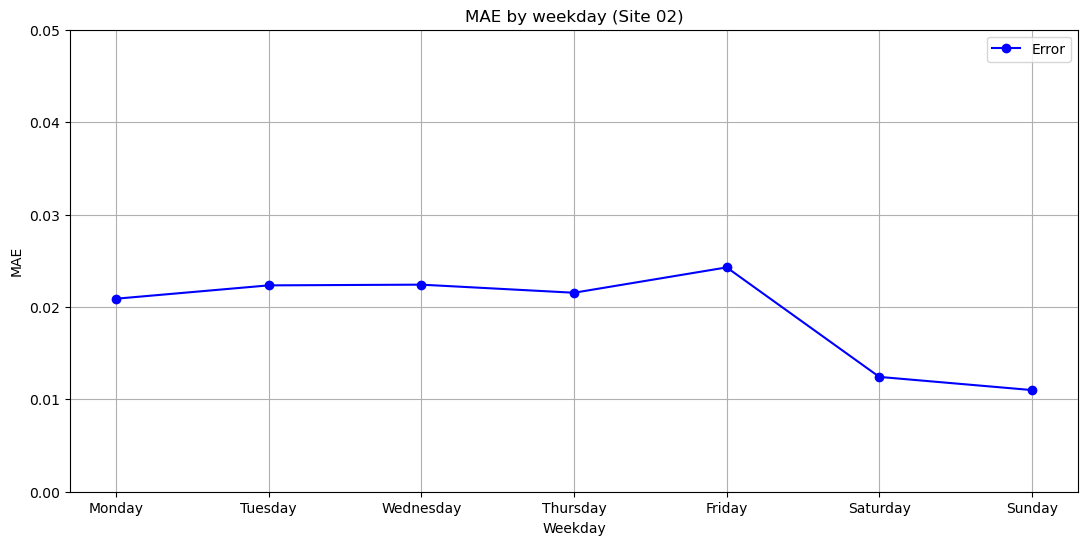

In [64]:
# Convert the residuals to absolutes and get the average
test_data2['residuals'] = test_data2['residuals'].abs()
weekday_avg = test_data2.groupby('weekday').mean(numeric_only=True)
weekday_avg = weekday_avg.reset_index()

# Sort weekdays 
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_avg['weekday'] = pd.Categorical(weekday_avg['weekday'], categories=weekday_order, ordered=True)
weekday_avg = weekday_avg.sort_values('weekday')

# Plotting
plt.figure(figsize=(13, 6))
plt.plot(weekday_avg['weekday'], weekday_avg['residuals'], marker='o', label='Error',color='blue')
plt.xlabel('Weekday')
plt.ylabel('MAE')
plt.ylim(0,0.05)
plt.title('MAE by weekday (Site 02)')
plt.legend()
plt.grid(True)
plt.show()

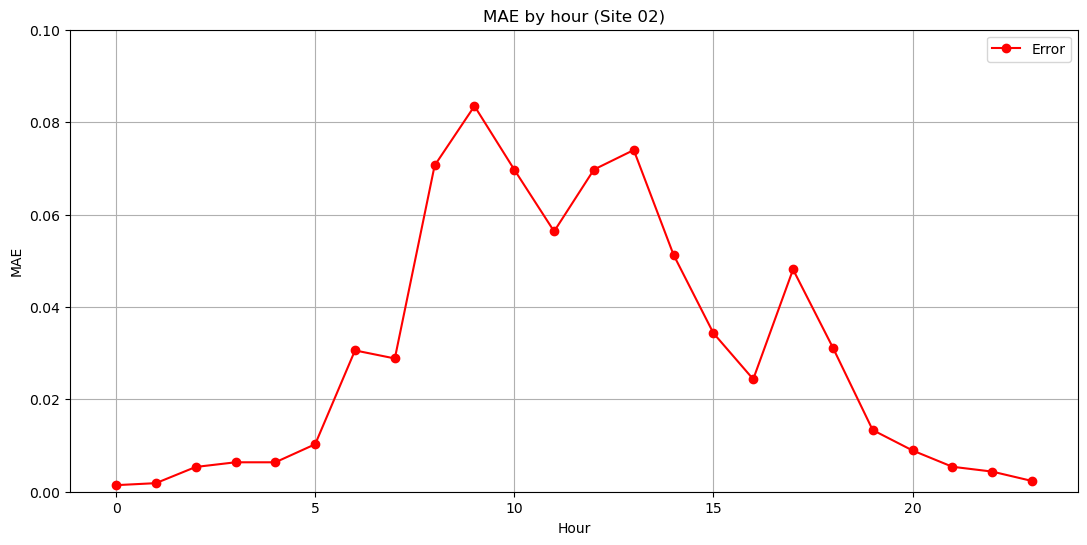

In [60]:
# Convert the residuals to absolutes and get the average
test_data1['hour'] = test_data1['timestamp'].dt.hour
hourly_avg = test_data1.groupby('hour').mean(numeric_only=True)
hourly_avg = hourly_avg.reset_index()



# Plotting
plt.figure(figsize=(13, 6))
plt.plot(hourly_avg['hour'], hourly_avg['residuals'], marker='o', label='Error',color='red')
plt.xlabel('Hour')
plt.ylim(0,0.1)
plt.ylabel('MAE')
plt.title('MAE by hour (Site 02)')
plt.legend()
plt.grid(True)
plt.show()

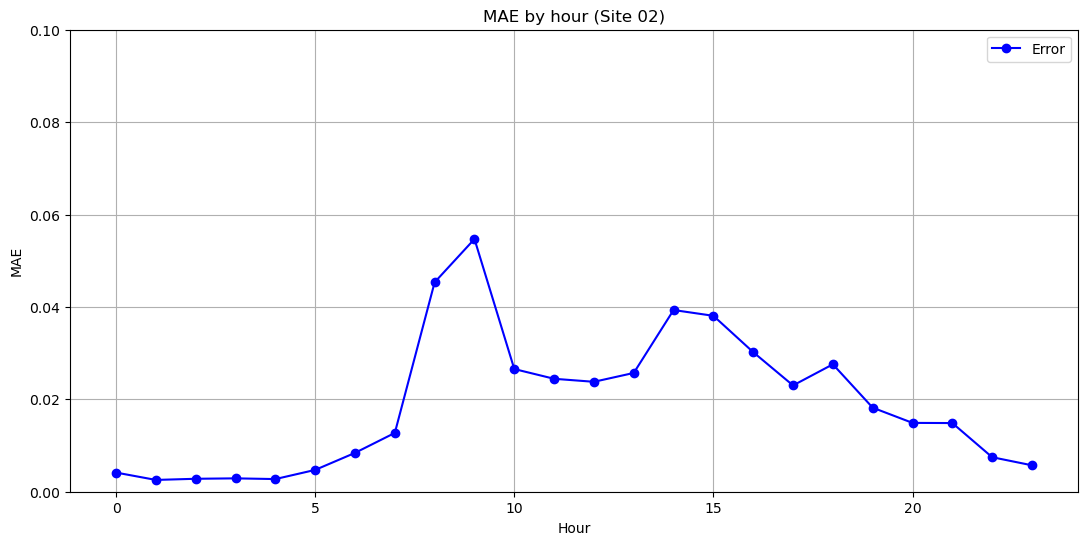

In [61]:
# Convert the residuals to absolutes and get the average
test_data2['hour'] = test_data2['timestamp'].dt.hour
hourly_avg = test_data2.groupby('hour').mean(numeric_only=True)
hourly_avg = hourly_avg.reset_index()



# Plotting
plt.figure(figsize=(13, 6))
plt.plot(hourly_avg['hour'], hourly_avg['residuals'], marker='o', label='Error',color='blue')
plt.xlabel('Hour')
plt.ylim(0,0.1)
plt.ylabel('MAE')
plt.title('MAE by hour (Site 02)')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
# Save the model
model.save('my_lstm_model.keras')

# Load the model
loaded_model = load_model('my_lstm_model.keras')

<div>
    <span style ="font-size: 40px; font-weight: bold; color: #8EB944">
        Grid Search
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [50]:
num_features = X_train.shape[2]
num_features

15

In [55]:
# Define the hyperparameter tuning function
def build_model(hp):
    model = Sequential()
    
    # Input Layer
    model.add(LSTM(
        units=hp.Int('units_1', min_value=8, max_value=64, step=16),
        activation='tanh',
        return_sequences=True,  # Keep sequences for stacking LSTMs
        input_shape=(sequence_length, num_features)
    ))
    
    # Optional Second LSTM Layer
    if hp.Boolean('add_second_lstm'):
        model.add(LSTM(
            units=hp.Int('units_2', min_value=8, max_value=64, step=16),
            activation='tanh'
        ))
    
    # Dropout Layer
    model.add(Dropout(rate=hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)))
    
    # Dense Hidden Layer
    model.add(Dense(
        units=hp.Int('dense_units', min_value=8, max_value=64, step=16),
        activation='relu'
    ))
    
    # Output Layer for regression
    model.add(Dense(1))
    
    # Compile the model
    model.compile(
        optimizer=RMSprop(
            learning_rate=hp.Float('learning_rate', min_value=0.0001, max_value=0.01, sampling='log')
        ),
        loss='mae',
        metrics=['mae']
    )
    return model


# Set up Keras Tuner for Random Search
tuner = RandomSearch(
    build_model,
    objective='val_loss',  # Minimize validation loss
    max_trials=100,         # Number of models to try
    executions_per_trial=2, # Number of times each model is trained
    directory='lstm_tuning',
    project_name='model_covid_filled_final'
)

# Search Space Summary
tuner.search_space_summary()

# Prepare the Data (Replace this with your actual data)
sequence_length = 24  # Example sequence length


# Start the Hyperparameter Tuning
tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=4,
    batch_size=32
)

# Print the Best Hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
print(f"Units Layer 1: {best_hps.get('units_1')}")
if best_hps.get('add_second_lstm'):
    print(f"Units Layer 2: {best_hps.get('units_2')}")
print(f"Dropout Rate: {best_hps.get('dropout_rate')}")
print(f"Dense Units: {best_hps.get('dense_units')}")
print(f"Learning Rate: {best_hps.get('learning_rate')}")

# Build and Train the Best Model
best_model = tuner.hypermodel.build(best_hps)
early_stopping = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
history = best_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    callbacks=[early_stopping],
    batch_size=32
)

# Evaluate the Best Model
loss, mae = best_model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss}, Validation MAE: {mae}")

Reloading Tuner from lstm_tuning/model_covid_filled_final/tuner0.json
Search space summary
Default search space size: 6
units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 64, 'step': 16, 'sampling': 'linear'}
add_second_lstm (Boolean)
{'default': False, 'conditions': []}
dropout_rate (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
dense_units (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 64, 'step': 16, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}
units_2 (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 64, 'step': 16, 'sampling': 'linear'}
Best Hyperparameters:
Units Layer 1: 40
Units Layer 2: 56
Dropout Rate: 0.30000000000000004
Dense Units: 24
Learning Rate: 0.00263103928490968
Epoch 1/100
615/615 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss